This is my Jupyter notebook for all the calculatios regarding the Case Study for data sets with several industries behaviours.
As a briefing for following design I included some libraries such as :
pandas, numpy and matplotlib.

There are code slices that allow clean data, perform specific calculations and others allow iteration per industry.

In [4]:
import pandas as pd
import numpy as np 
df = pd.read_csv('./Business.csv')
df #display the dataframe

,ID,INDUSTRY,1/2/2022,1/3/2022,1/4/2022,1/5/2022,1/6/2022,1/7/2022,1/8/2022,1/9/2022,...,1/7/2023,1/8/2023,1/9/2023,1/10/2023,1/11/2023,1/12/2023,1/1/2024,1/2/2024,1/3/2024,1/4/2024
0,6300005,Automobiles & Components,NaN,"$2,074.00","$1,829.00","$2,048.00","$2,833.00","$1,363.20","$2,003.00","$2,963.00",...,NaN,$838.20,$921.40,$921.40,"$1,440.70","$1,165.46","$2,308.90","$1,082.96","$5,513.96","$3,650.50"
1,6300007,"Restaurant, Take-out & Catering",$521.00,$378.00,$981.00,$333.00,$516.00,$642.80,$303.10,$306.10,...,NaN,$31.00,NaN,NaN,NaN,$186.15,NaN,NaN,NaN,NaN
2,6300008,Food & Staples Retailing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,$340.60,$340.60,$0.00,$715.82,$189.75,NaN,NaN,$154.98
3,6300012,E-commerce,$0.00,$0.00,$0.00,$0.00,$0.00,NaN,NaN,NaN,...,NaN,$75.80,NaN,NaN,NaN,$90.48,NaN,NaN,NaN,NaN
4,6300015,Retail & Wholesale,NaN,$112.00,$316.00,$405.00,$119.00,$314.40,$136.00,NaN,...,$184.50,$249.10,NaN,NaN,NaN,NaN,NaN,$311.81,$189.31,$638.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3760,6306390,Media & Entertainment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,$0.00,NaN,NaN,NaN,$0.00,NaN,NaN,$348.24
3761,6306391,Materials,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,$0.00,NaN,NaN,NaN,$0.00,NaN,NaN,$350.10
3762,6306394,Retail & Wholesale,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,$0.00,NaN,NaN,NaN,$0.00,NaN,NaN,"$1,269.50"
3763,6306401,Automobiles & Components,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,$0.00,NaN,NaN,NaN,$0.00,NaN,NaN,"$2,124.98"


Basic descriptive analysis.
For following analysis I selected to show total incomes per industry, also  for the mean
Also i think is relevant a participation percentage per industry
For last analyze spread behaviour

In [6]:
#Following script allows to clean data, since there are some characters that mdoes not allow perform calculation between cells

#  Clean columns (Remove $ and commas, also we need to  change data type to number)
period_cols = [c for c in df.columns if c not in ['ID', 'INDUSTRY']]

for c in period_cols:
    df[c] = df[c].astype(str).str.replace(r'[\$,]', '', regex=True)
    df[c] = pd.to_numeric(df[c], errors='coerce')

#  Reestructurar la tabla para tener en 2 columnas el periodo y el valor de la transacción, a formato largo (una fila por empresa-periodo-ingreso)
df_long = df.melt(id_vars=['ID', 'INDUSTRY'], value_vars=period_cols,
                   var_name='PERIOD', value_name='TV($)')
df_long['PERIOD'] = pd.to_datetime(df_long['PERIOD'], format='%d/%m/%Y')
df_long = df_long.dropna(subset=['TV($)'])  # quita meses sin dato

df_long #This is the variable that we keep using for further analysis


,ID,INDUSTRY,PERIOD,TV($)
1,6300007,"Restaurant, Take-out & Catering",2022-02-01,521.00
3,6300012,E-commerce,2022-02-01,0.00
6,6300019,Consumer Durables & Apparel,2022-02-01,533.00
7,6300021,E-commerce,2022-02-01,559.00
8,6300024,"Restaurant, Take-out & Catering",2022-02-01,7229.00
...,...,...,...,...
101650,6306390,Media & Entertainment,2024-04-01,348.24
101651,6306391,Materials,2024-04-01,350.10
101652,6306394,Retail & Wholesale,2024-04-01,1269.50
101653,6306401,Automobiles & Components,2024-04-01,2124.98


In [7]:
#  Análisis descriptivo básico por industria
resumen = df_long.groupby('INDUSTRY')['TV($)'].agg(
    Total_tv='sum',
    Average_tv='mean',
    desviacion_std='std',
    min='min',
    max='max',
    num_records='count'
).sort_values('Total_tv', ascending=False)

# Participación (%) de cada industria sobre el ingreso total
resumen['Contribution_%'] = (resumen['Total_tv'] / resumen['Total_tv'].sum() * 100).round(2)

print(resumen.round(2))


                                                   Total_tv  Average_tv  \
INDUSTRY                                                                  
Restaurant, Take-out & Catering                 13785802.47     1601.32   
E-commerce                                      10648449.03     1919.68   
Transportation & Logistic Service               10063178.95    11218.71   
Food & Staples Retailing                         6794470.67     2034.88   
Construction, Machinery & Infrastructure         6704979.43     5912.68   
Retail & Wholesale                               6501324.98     1679.49   
Household & Personal Products                    4338574.45     1433.77   
Health Care Equipment & Services                 4018696.53     2324.29   
Automobiles & Components                         2568323.98     1532.41   
Consumer Durables & Apparel                      2373549.01     1138.94   
Materials                                        1985906.09     1862.95   
Professional Services    

A wider view  Pareto analysis
80 % is explained by the 20 %, in terms of business we define that aprox 20 % of products represents 80 % of sales.
For this particular analysis we figure it pur that 7 (aprox the 30 % of the industries) industries represents the 75.54% of the Transaction values
                                                participacion_%  
INDUSTRY                                                         
Restaurant, Take-out & Catering                           17.70  
E-commerce                                                13.67  
Transportation & Logistic Service                         12.92  
Food & Staples Retailing                                   8.72  
Construction, Machinery & Infrastructure                   8.61  
Retail & Wholesale                                         8.35  
Household & Personal Products                              5.57 


In [ ]:
# Serie de ingreso total por industria y periodo
serie = df_long.groupby(['INDUSTRY', 'PERIOD'])['TV($)'].sum().reset_index()

# Pivot: filas = periodo, columnas = industria (para graficar/comparar fácil)
pivot = serie.pivot(index='PERIOD', columns='INDUSTRY', values='TV($)').sort_index()

#  % de cambio periodo a periodo (tasa de crecimiento)
pct_cambio = pivot.pct_change().round(3)

#  Promedio móvil de 3 periodos (suaviza la serie)
promedio_movil = pivot.rolling(3).mean()

#  Periodo de mayor y menor ingreso por industria
max_periodo = pivot.idxmax()  # fecha con mayor ingreso, por industria
min_periodo = pivot.idxmin()  # fecha con menor ingreso, por industria

resumen_extremos = pd.DataFrame({
    'periodo_max': max_periodo,
    'ingreso_max': pivot.max(),
    'periodo_min': min_periodo,
    'ingreso_min': pivot.min()
})

# 4. Crecimiento total del periodo inicial al final, por industria
crecimiento_total = ((pivot.iloc[-1] - pivot.iloc[0]) / pivot.iloc[0] * 100).round(2)
crecimiento_total = crecimiento_total.sort_values(ascending=False).rename('crecimiento_%_total')

print(resumen_extremos)
print(crecimiento_total)

                                               periodo_max  ingreso_max  \
INDUSTRY                                                                  
Automobiles & Components                        2023-12-01    158213.13   
Construction, Machinery & Infrastructure        2024-01-01    439428.36   
Consumer Durables & Apparel                     2023-09-01    160559.06   
Consumer Services                               2023-12-01    117932.16   
E-commerce                                      2023-12-01    758667.96   
Energy                                          2024-02-01      4366.35   
Finance                                         2024-02-01     13399.14   
Food & Staples Retailing                        2023-12-01    370622.20   
Health Care Equipment & Services                2024-04-01    261169.94   
Household & Personal Products                   2022-06-01    689918.00   
Insurance                                       2023-03-01      9115.85   
Materials                

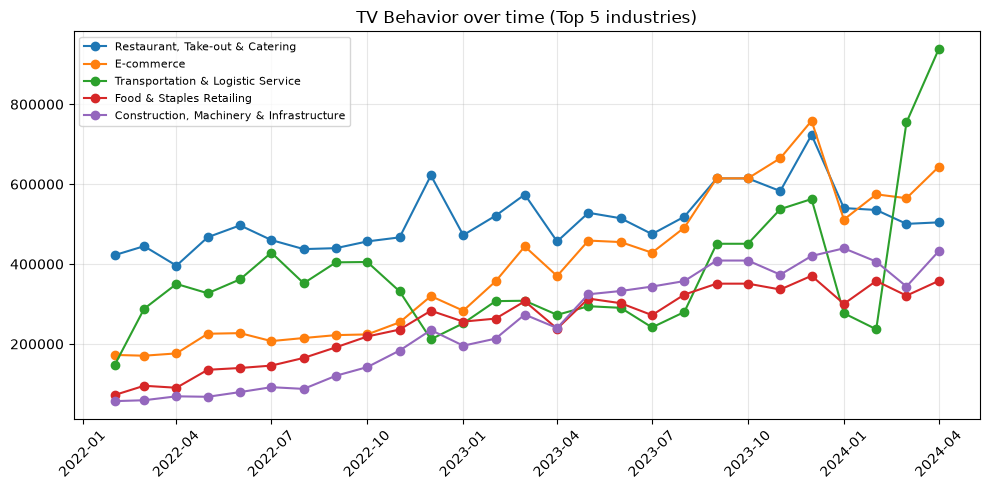

In [60]:
#Graficas

import matplotlib.pyplot as plt

# Serie agregada: ingreso total por industria y periodo
serie = df_long.groupby(['INDUSTRY', 'PERIOD'])['TV($)'].sum().reset_index()
pivot = serie.pivot(index='PERIOD', columns='INDUSTRY', values='TV($)').sort_index()

top5 = pivot.sum().sort_values(ascending=False).head(5).index.tolist()

#  TENDENCIA TEMPORAL 

# 1. Evolución del ingreso por periodo (líneas, top 5 industrias)
fig, ax = plt.subplots(figsize=(10, 5))
for industria in top5:
    ax.plot(pivot.index, pivot[industria], marker='o', label=industria)
ax.set_title('TV Behavior over time (Top 5 industries)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

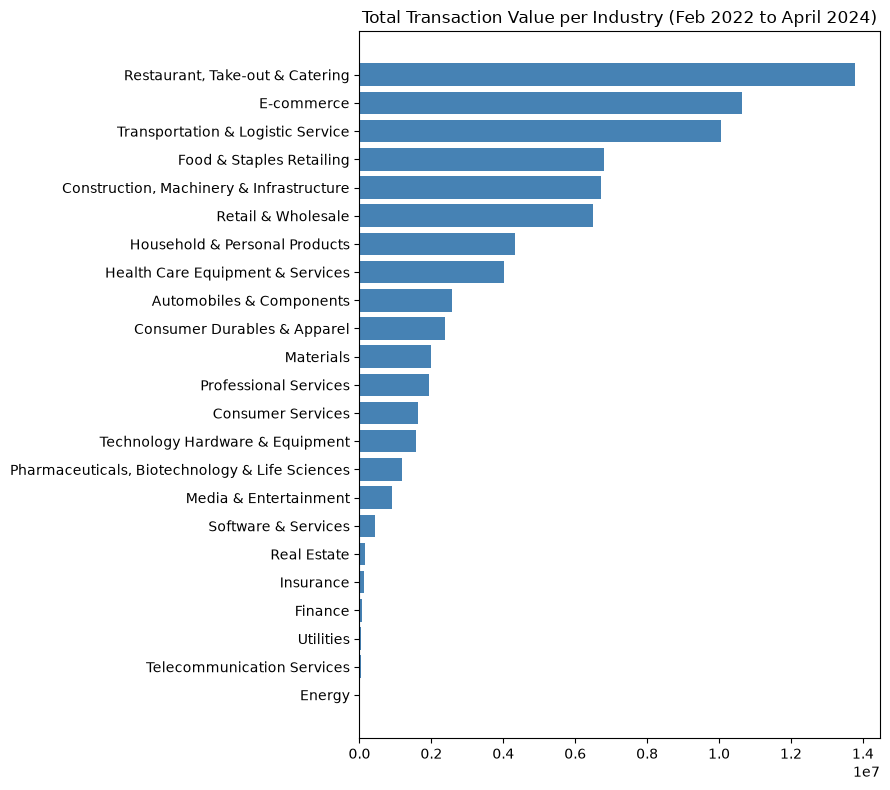

In [61]:
ranking = pivot.sum().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(ranking.index, ranking.values, color='steelblue')
ax.set_title('Total Transaction Value per Industry (Feb 2022 to April 2024)')
plt.tight_layout()
plt.show()

In [62]:


def tabla_ingreso_mensual(index_industria, pivot=pivot, ranking=ranking):
    industria = ranking.index[index_industria]
    tabla = pivot[[industria]].dropna().reset_index()
    tabla.columns = ['PERIOD', 'TV']
    tabla['PERIOD'] = tabla['PERIOD'].dt.strftime('%Y-%m')
    print(f"Industry: {industria}")
    return tabla

#  Cambia solo esta variable para ver otra industria 
INDUSTRIA_INDEX = 0   # 0 = Restaurant, Take-out & Catering (mayor ingreso)

tabla = tabla_ingreso_mensual(INDUSTRIA_INDEX)
print(tabla)

Industry: Energy
     PERIOD       TV
0   2022-02     0.00
1   2022-03     0.00
2   2022-04     0.00
3   2022-05     0.00
4   2022-06    51.00
5   2022-07   261.80
6   2022-08   407.00
7   2022-10   251.00
8   2022-11   486.20
9   2022-12   945.60
10  2023-01   297.50
11  2023-02   494.90
12  2023-03   597.10
13  2023-04   127.40
14  2023-05  1195.02
15  2023-06   844.60
16  2023-08    71.60
17  2023-09   981.27
18  2023-10   981.27
19  2023-11    58.60
20  2023-12  1404.47
21  2024-01  1505.64
22  2024-02  4366.35
23  2024-03  2098.71
24  2024-04  3564.42


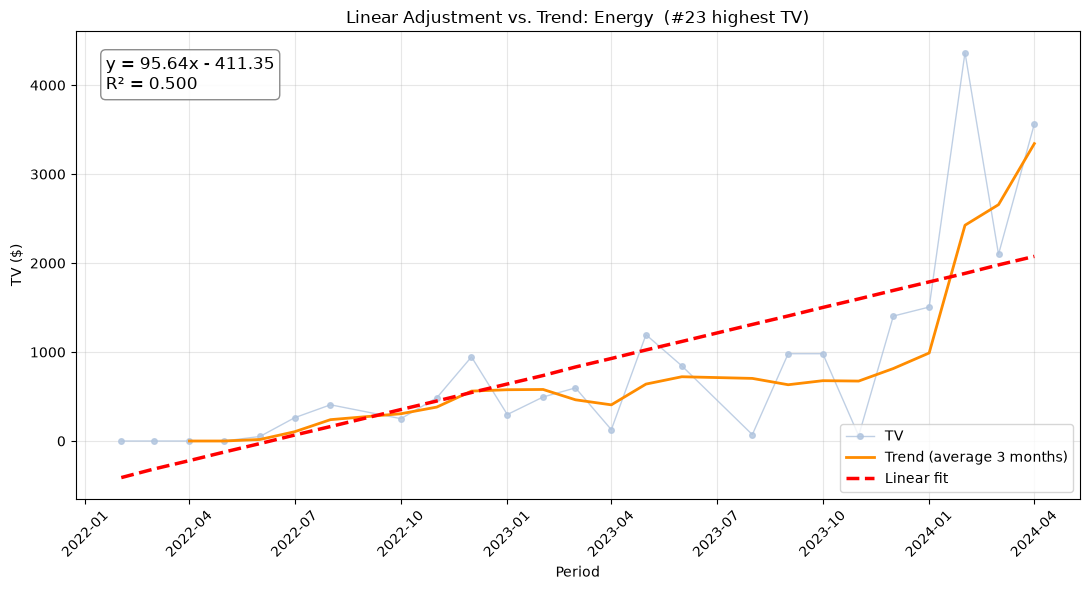

{'industria': 'Energy', 'ecuacion': 'y = 95.64x - 411.35', 'r2': np.float64(0.5), 'pendiente': np.float64(95.64), 'intercepto': np.float64(-411.35)}


In [ ]:
#Graficas de ajuste lineal y tendencia

def analizar_industria(index_industria, pivot=pivot, ranking=ranking):
    """
    index_industria: posición en el ranking (0 = mayor ingreso total, 1 = segunda, etc.)
    """
    industria = ranking.index[index_industria]

    y = pivot[industria].values
    mask = ~np.isnan(y)
    x = np.arange(len(pivot))[mask]
    yf = y[mask]
    fechas = pivot.index[mask]

    def r2_score(y, pred):
        ss_res = np.sum((y - pred)**2)
        ss_tot = np.sum((y - y.mean())**2)
        return 1 - ss_res / ss_tot

    coef_lin = np.polyfit(x, yf, 1)
    a, b = coef_lin
    pred_lin = np.polyval(coef_lin, x)
    r2_lin = r2_score(yf, pred_lin)
    signo = '+' if b >= 0 else '-'
    ecuacion = f"y = {a:,.2f}x {signo} {abs(b):,.2f}"

    tendencia = pd.Series(yf, index=fechas).rolling(3).mean()

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(fechas, yf, 'o-', color='lightsteelblue', label='TV', markersize=4, linewidth=1, alpha=0.8)
    ax.plot(fechas, tendencia, color='darkorange', linewidth=2, label='Trend (average 3 months)') #this is to provide a more smoother to graph
    ax.plot(fechas, pred_lin, '--', color='red', linewidth=2.5, label='Linear fit')

    ax.text(0.03, 0.95, f'{ecuacion}\nR² = {r2_lin:.3f}',
            transform=ax.transAxes, fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.9))

    ax.set_title(f'Linear Adjustment vs. Trend: {industria}  (#{index_industria + 1} highest TV)')
    ax.set_xlabel('Period'); ax.set_ylabel('TV ($)')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return {'industria': industria, 'ecuacion': ecuacion, 'r2': round(r2_lin, 3),
            'pendiente': round(a, 2), 'intercepto': round(b, 2)}

# USO: cambia el índice para cualquier industria 
resultado = analizar_industria(22)   # 0 = top 1 (Restaurant, Take-out & Catering)
print(resultado)

=== PEAKS ===
      date   Real_TV  expected_TV  residual
2022-12-01 621841.38     493423.0  128418.0
2023-03-01 574018.14     510585.0   63433.0
2023-09-01 614370.71     544910.0   69461.0
2023-10-01 614370.71     550630.0   63740.0
2023-12-01 723187.80     562072.0  161116.0

=== VALLEYS ===
      date   Real_TV  expected_TV  residual
2023-04-01 456536.39     516306.0  -59770.0
2023-07-01 475011.10     533468.0  -58457.0
2024-03-01 500617.23     579234.0  -78617.0
2024-04-01 504380.89     584955.0  -80574.0

=== Average residual per month ===
           mean  count
month                 
1      -27192.0      2
2      -11885.0      3
3       -4112.0      3
4      -64011.0      3
5       10065.0      2
6       12334.0      2
7      -31602.0      2
8      -26868.0      2
9       16504.0      2
10      19220.0      2
11       2784.0      2
12     144767.0      2


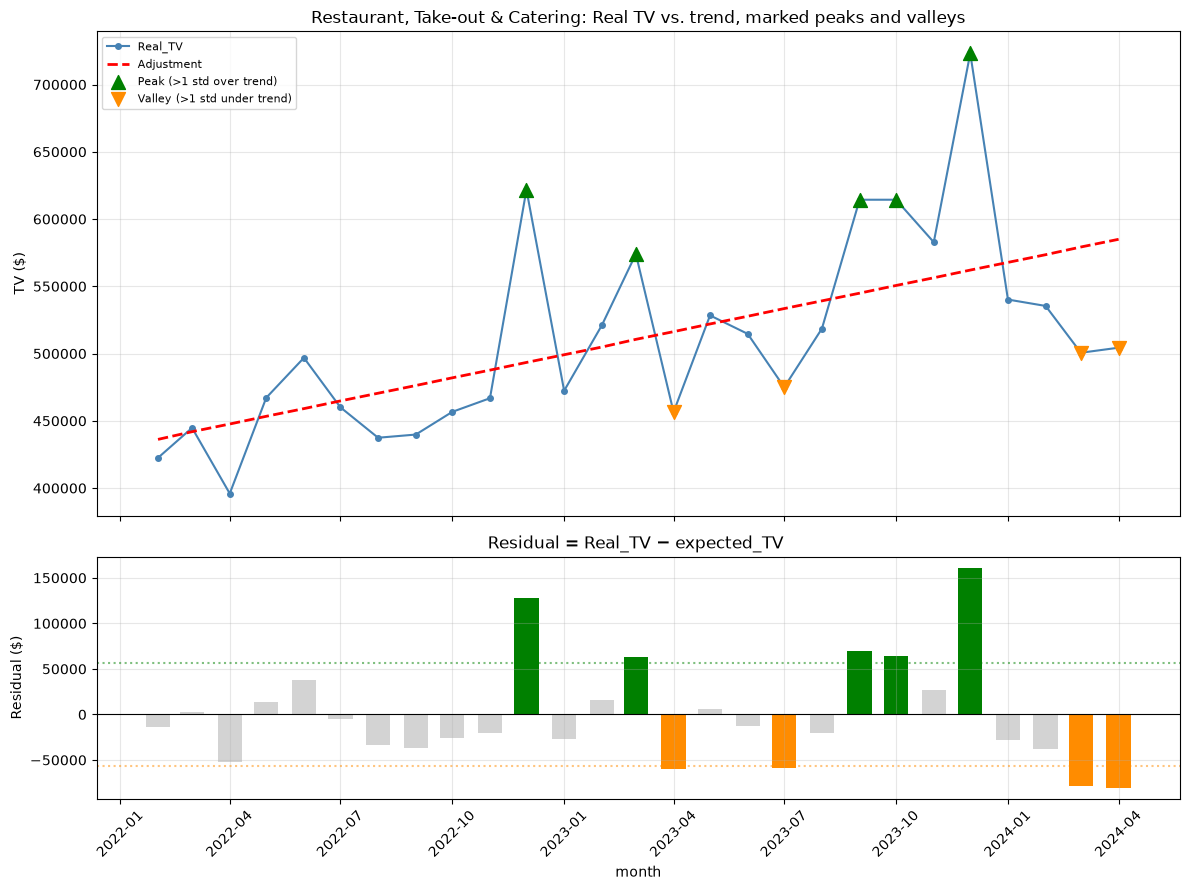

In [ ]:


#  Seleccionar industria para iterar
industria = 'Restaurant, Take-out & Catering'   # <- cambia aquí la industria que quieras analizar

y = pivot[industria].values
mask = ~np.isnan(y)
x = np.arange(len(pivot))[mask]      
yf = y[mask]
fechas = pivot.index[mask]

# . AJUSTE LINEAL 
coef_lin = np.polyfit(x, yf, 1)
pred_lin = np.polyval(coef_lin, x)

#  RESIDUALES 
residuales = yf - pred_lin

df_res = pd.DataFrame({'date': fechas, 'Real_TV': yf, 'expected_TV': pred_lin.round(0),
                        'residual': residuales.round(0), 'month': fechas.month})

# PICOS Y VALLES 
std_res = residuales.std()
es_pico = residuales > std_res
es_valle = residuales < -std_res

print("=== PEAKS ===")
print(df_res[es_pico][['date', 'Real_TV', 'expected_TV', 'residual']].to_string(index=False))
print("\n=== VALLEYS ===")
print(df_res[es_valle][['date', 'Real_TV', 'expected_TV', 'residual']].to_string(index=False))

#  PATRÓN ESTACIONAL POR MES CALENDARIO 
patron_mensual = df_res.groupby('month')['residual'].agg(['mean', 'count']).round(0)
print("\n=== Average residual per month ===")
print(patron_mensual)

#  8. GRÁFICA 
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True, height_ratios=[2, 1])

ax1.plot(fechas, yf, 'o-', color='steelblue', label='Real_TV', markersize=4)
ax1.plot(fechas, pred_lin, '--', color='red', linewidth=2, label='Adjustment')
ax1.scatter(fechas[es_pico], yf[es_pico], color='green', s=100, zorder=5, marker='^', label='Peak (>1 std over trend)')
ax1.scatter(fechas[es_valle], yf[es_valle], color='darkorange', s=100, zorder=5, marker='v', label='Valley (>1 std under trend)')
ax1.set_ylabel('TV ($)')
ax1.set_title(f'{industria}: Real TV vs. trend, marked peaks and valleys')
ax1.legend(fontsize=8, loc='upper left')
ax1.grid(alpha=0.3)

colores = ['green' if r > std_res else ('darkorange' if r < -std_res else 'lightgray') for r in residuales]
ax2.bar(fechas, residuales, color=colores, width=20)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.axhline(std_res, color='green', linestyle=':', alpha=0.5)
ax2.axhline(-std_res, color='darkorange', linestyle=':', alpha=0.5)
ax2.set_ylabel('Residual ($)')
ax2.set_xlabel('month')
ax2.set_title('Residual = Real_TV − expected_TV ')
ax2.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [8]:


industria = 'E-commerce'
y = pivot[industria].values
mask = ~np.isnan(y)
x = np.arange(len(pivot))[mask]
yf = y[mask]
fechas = pivot.index[mask]

# --- Ajuste lineal ---
coef_lin = np.polyfit(x, yf, 1)
a, b = coef_lin
pred_lin = np.polyval(coef_lin, x)

def r2_score(y, pred):
    ss_res = np.sum((y - pred)**2)
    ss_tot = np.sum((y - y.mean())**2)
    return 1 - ss_res / ss_tot
r2 = r2_score(yf, pred_lin)

# --- Error estándar del modelo (para el intervalo de confianza) ---
n = len(x)
dof = n - 2
s_err = np.sqrt(np.sum((yf - pred_lin)**2) / dof)

# --- Proyección a 12 meses ---
# ... (mismo bloque de ajuste lineal, proyección e intervalo de confianza de antes) ...

# --- Totales para destacar ---
ingreso_total_proyectado = y_futuro.sum()
ingreso_total_actual_12m = yf[-12:].sum()
ingreso_ultimo_mes_proyectado = y_futuro[-1]
crecimiento_pct = (ingreso_total_proyectado / ingreso_total_actual_12m - 1) * 100

fig, ax = plt.subplots(figsize=(12.5, 6.5))
ax.plot(fechas, yf, 'o-', color='steelblue', label='Ingreso real', markersize=4)
ax.plot(fechas, pred_lin, color='steelblue', linestyle=':', alpha=0.5)
ax.plot(fechas_futuras, y_futuro, 'o--', color='red', label='Proyección (12 meses)', markersize=4)
ax.fill_between(fechas_futuras, ci_lower, ci_upper, color='red', alpha=0.15, label='Intervalo de confianza 95%')
ax.axvline(fechas[-1], color='gray', linestyle=':', alpha=0.7)

# Punto y etiqueta del último mes proyectado
ax.scatter([fechas_futuras[-1]], [ingreso_ultimo_mes_proyectado], color='darkred', s=60, zorder=5)
ax.annotate(f'${ingreso_ultimo_mes_proyectado:,.0f}\n(mes 12)',
            xy=(fechas_futuras[-1], ingreso_ultimo_mes_proyectado),
            xytext=(15, -25), textcoords='offset points', fontsize=9,
            color='darkred', fontweight='bold')

# Caja destacada con el INGRESO TOTAL acumulado del periodo proyectado
texto_total = (f'INGRESO TOTAL PROYECTADO (12 meses)\n'
               f'${ingreso_total_proyectado:,.0f}\n'
               f'vs. últimos 12 meses reales: ${ingreso_total_actual_12m:,.0f}  ({crecimiento_pct:+.1f}%)')
ax.text(0.5, -0.28, texto_total, transform=ax.transAxes, fontsize=11,
        ha='center', va='top', color='white', fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='darkred', edgecolor='none'))

# Ecuación (reubicada arriba a la derecha para no chocar con la leyenda)
ax.text(0.98, 0.97, f'{ecuacion}\nR² = {r2:.3f}',
        transform=ax.transAxes, fontsize=10, verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.9))

ax.set_title(f'Proyección a 1 año: {industria}', fontsize=13)
ax.set_xlabel('Mes'); ax.set_ylabel('Ingreso mensual ($)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(fechas[0] - pd.DateOffset(months=1), fechas_futuras[-1] + pd.DateOffset(months=3))
plt.xticks(rotation=45)
plt.tight_layout()
plt.subplots_adjust(bottom=0.32)  # espacio para la caja de total
plt.show()

NameError: name 'pivot' is not defined

Calculate your average order value (AOV) by dividing your total revenue by the total number of orders over a specific time frame. For example, if your store makes $5,000 from 100 orders, your AOV is $50.

When one industry has a higher Average Order Value (AOV) than another, it primarily means customers spend more money per transaction in that industry

In [11]:
import pandas as pd
import numpy as np
orders = pd.read_csv('./Orders.csv')
orders #display the dataframe

,ID,INDUSTRY,1/2/2022,1/3/2022,1/4/2022,1/5/2022,1/6/2022,1/7/2022,1/8/2022,1/9/2022,...,1/4/2024,1/5/2024,1/6/2024,1/7/2024,1/8/2024,1/9/2024,1/10/2024,1/11/2024,1/12/2024,1/1/2025
0,6300005,Automobiles & Components,NaN,2.0,2.0,3.0,4.0,1.0,2.0,4.0,...,7.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6300007,"Restaurant, Take-out & Catering",11.0,7.0,13.0,4.0,7.0,11.0,5.0,4.0,...,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,6300008,Food & Staples Retailing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6300012,E-commerce,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,...,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,6300015,Retail & Wholesale,NaN,1.0,3.0,3.0,1.0,2.0,1.0,NaN,...,6.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3760,6306390,Media & Entertainment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3761,6306391,Materials,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3762,6306394,Retail & Wholesale,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3763,6306401,Automobiles & Components,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,15.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
periodo_cols_o = [c for c in orders.columns if c not in ['ID', 'INDUSTRY']]
for c in periodo_cols_o:
    orders[c] = pd.to_numeric(orders[c], errors='coerce')

orders_long = orders.melt(id_vars=['ID', 'INDUSTRY'], value_vars=periodo_cols_o,
                            var_name='PERIOD', value_name='ORDERS')
orders_long['PERIOD'] = pd.to_datetime(orders_long['PERIOD'], format='%d/%m/%Y')
orders_long

,ID,INDUSTRY,PERIOD,ORDERS
0,6300005,Automobiles & Components,2022-02-01,NaN
1,6300007,"Restaurant, Take-out & Catering",2022-02-01,11.0
2,6300008,Food & Staples Retailing,2022-02-01,NaN
3,6300012,E-commerce,2022-02-01,0.0
4,6300015,Retail & Wholesale,2022-02-01,NaN
...,...,...,...,...
135535,6306390,Media & Entertainment,2025-01-01,NaN
135536,6306391,Materials,2025-01-01,NaN
135537,6306394,Retail & Wholesale,2025-01-01,NaN
135538,6306401,Automobiles & Components,2025-01-01,NaN


In [ ]:
resumen_pedidos = orders_long.groupby('INDUSTRY')['ORDERS'].agg(
    Total_orders='sum',
    pedidos_promedio_mensual='mean',
    num_meses_con_datos='count'
).round(1)

resumen_pedidos['Contribution_%'] = (resumen_pedidos['Total_orders'] / resumen_pedidos['Total_orders'].sum() * 100).round(2)
resumen_pedidos = resumen_pedidos.sort_values('Total_orders', ascending=False)

print(resumen_pedidos)
print("TOTAL GENERAL DE PEDIDOS:", int(resumen_pedidos['Total_orders'].sum()))

                                                Total_orders  \
INDUSTRY                                                       
Restaurant, Take-out & Catering                     134155.0   
E-commerce                                           72048.0   
Transportation & Logistic Service                    54271.0   
Food & Staples Retailing                             52786.0   
Retail & Wholesale                                   43387.0   
Construction, Machinery & Infrastructure             38124.0   
Health Care Equipment & Services                     25010.0   
Household & Personal Products                        22754.0   
Automobiles & Components                             18224.0   
Consumer Durables & Apparel                          15301.0   
Professional Services                                13906.0   
Materials                                            12910.0   
Technology Hardware & Equipment                      12834.0   
Consumer Services                       

0 - Restaurant, Take-out & Catering
1 - E-commerce
2 - Transportation & Logistic Service
3 - Food & Staples Retailing
4 - Retail & Wholesale
5 - Construction, Machinery & Infrastructure
6 - Health Care Equipment & Services
7 - Household & Personal Products
8 - Automobiles & Components
9 - Consumer Durables & Apparel
10 - Professional Services
11 - Materials
12 - Technology Hardware & Equipment
13 - Consumer Services
14 - Pharmaceuticals, Biotechnology & Life Sciences
15 - Media & Entertainment
16 - Software & Services
17 - Real Estate
18 - Insurance
19 - Finance
20 - Utilities
21 - Telecommunication Services
22 - Energy


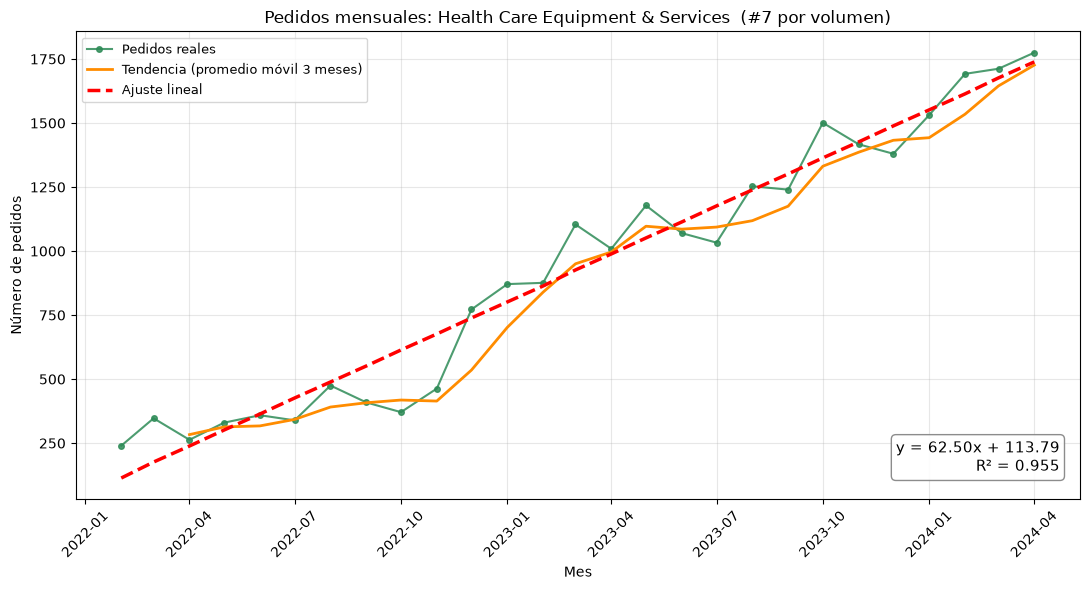

{'industria': 'Health Care Equipment & Services', 'ecuacion': 'y = 62.50x + 113.79', 'r2': np.float64(0.955)}


In [ ]:
orders_long = orders_long[orders_long['PERIOD'] <= '2024-04-01'] #Since there are more data for orders, we will adapt the same range as in TV

serie_pedidos = orders_long.groupby(['INDUSTRY', 'PERIOD'])['ORDERS'].sum().reset_index()
pivot_pedidos = serie_pedidos.pivot(index='PERIOD', columns='INDUSTRY', values='ORDERS').sort_index()
ranking_pedidos = pivot_pedidos.sum().sort_values(ascending=False)

for i, industria in enumerate(ranking_pedidos.index):
    print(i, '-', industria)

# ============ 3. FUNCIÓN REUTILIZABLE: PLOT POR ÍNDICE DE INDUSTRIA ============
def analizar_pedidos_industria(index_industria, pivot=pivot_pedidos, ranking=ranking_pedidos):
    industria = ranking.index[index_industria]
    y = pivot[industria].values
    mask = ~np.isnan(y)
    x = np.arange(len(pivot))[mask]
    yf = y[mask]
    fechas = pivot.index[mask]

    def r2_score(y, pred):
        ss_res = np.sum((y - pred)**2)
        ss_tot = np.sum((y - y.mean())**2)
        return 1 - ss_res / ss_tot

    coef_lin = np.polyfit(x, yf, 1)
    a, b = coef_lin
    pred_lin = np.polyval(coef_lin, x)
    r2_lin = r2_score(yf, pred_lin)
    signo = '+' if b >= 0 else '-'
    ecuacion = f"y = {a:,.2f}x {signo} {abs(b):,.2f}"

    tendencia = pd.Series(yf, index=fechas).rolling(3).mean()

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(fechas, yf, 'o-', color='seagreen', label='Pedidos reales', markersize=4, alpha=0.85)
    ax.plot(fechas, tendencia, color='darkorange', linewidth=2, label='Tendencia (promedio móvil 3 meses)')
    ax.plot(fechas, pred_lin, '--', color='red', linewidth=2.5, label='Ajuste lineal')

    ax.text(0.98, 0.05, f'{ecuacion}\nR² = {r2_lin:.3f}',
            transform=ax.transAxes, fontsize=11, verticalalignment='bottom', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray', alpha=0.9))

    ax.set_title(f'Pedidos mensuales: {industria}  (#{index_industria + 1} por volumen)')
    ax.set_xlabel('Mes'); ax.set_ylabel('Número de pedidos')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return {'industria': industria, 'ecuacion': ecuacion, 'r2': round(r2_lin, 3)}

# ============ 4. USO: cambia el índice para cualquier industria ============
resultado = analizar_pedidos_industria(6)   # 0 = top 1 en volumen de pedidos
print(resultado)

Now lets calculate Average Value Order (AVO)

In [ ]:
merged = pd.merge(df_long, orders_long[['ID', 'PERIOD', 'ORDERS']],
                   on=['ID', 'PERIOD'], how='inner')
merged

,ID,INDUSTRY,PERIOD,TV($),ORDERS
0,6300007,"Restaurant, Take-out & Catering",2022-02-01,521.00,11.0
1,6300012,E-commerce,2022-02-01,0.00,0.0
2,6300019,Consumer Durables & Apparel,2022-02-01,533.00,4.0
3,6300021,E-commerce,2022-02-01,559.00,6.0
4,6300024,"Restaurant, Take-out & Catering",2022-02-01,7229.00,105.0
...,...,...,...,...,...
39781,6306390,Media & Entertainment,2024-04-01,348.24,3.0
39782,6306391,Materials,2024-04-01,350.10,1.0
39783,6306394,Retail & Wholesale,2024-04-01,1269.50,6.0
39784,6306401,Automobiles & Components,2024-04-01,2124.98,15.0


In [ ]:
merged['AVO'] = merged['TV($)'] / merged['ORDERS']
merged.loc[merged['ORDERS'] == 0, 'AVO'] = np.nan  # evita división entre cero
merged.replace([np.inf, -np.inf], np.nan, inplace=True)

print(merged[['ID', 'INDUSTRY', 'PERIOD', 'TV($)', 'ORDERS', 'AVO']])

            ID                         INDUSTRY     PERIOD       TV($)  \
0      6300007  Restaurant, Take-out & Catering 2022-02-01      521.00   
1      6300012                       E-commerce 2022-02-01        0.00   
2      6300019      Consumer Durables & Apparel 2022-02-01      533.00   
3      6300021                       E-commerce 2022-02-01      559.00   
4      6300024  Restaurant, Take-out & Catering 2022-02-01     7229.00   
...        ...                              ...        ...         ...   
39781  6306390            Media & Entertainment 2024-04-01      348.24   
39782  6306391                        Materials 2024-04-01      350.10   
39783  6306394               Retail & Wholesale 2024-04-01     1269.50   
39784  6306401         Automobiles & Components 2024-04-01     2124.98   
39785    Total                              NaN 2024-04-01  5690233.95   

        ORDERS         AVO  
0         11.0   47.363636  
1          0.0         NaN  
2          4.0  133.2500

In [ ]:
#  TICKET PROMEDIO A NIVEL INDUSTRIA-MES 
# Suma ingreso y pedidos por industria-mes PRIMERO, luego se divide
# (más robusto que promediar razones individuales por negocio)
agg_industria_mes = merged.groupby(['INDUSTRY', 'PERIOD']).agg(
    ingreso_total=('TV($)', 'sum'),
    pedidos_total=('ORDERS', 'sum')
).reset_index()
agg_industria_mes['AOV'] = agg_industria_mes['ingreso_total'] / agg_industria_mes['pedidos_total']
agg_industria_mes.loc[agg_industria_mes['pedidos_total'] == 0, 'ticket_promedio'] = np.nan

#  RESUMEN: promedio, máximo y mínimo por industria 
resumen_industria = agg_industria_mes.groupby('INDUSTRY')['AOV'].agg(
    AOV='mean',
    AOV_max='max',
    AOV_min='min'
).round(2)

# En qué mes ocurrió el máximo y el mínimo
idx_max = agg_industria_mes.loc[agg_industria_mes.groupby('INDUSTRY')['AOV'].idxmax()]
idx_min = agg_industria_mes.loc[agg_industria_mes.groupby('INDUSTRY')['AOV'].idxmin()]
resumen_industria['mes_maximo'] = idx_max.set_index('INDUSTRY')['PERIOD'].dt.strftime('%Y-%m')
resumen_industria['mes_minimo'] = idx_min.set_index('INDUSTRY')['PERIOD'].dt.strftime('%Y-%m')

resumen_industria = resumen_industria.sort_values('AOV', ascending=False)
print(resumen_industria)

                                                   AOV  AOV_max  AOV_min  \
INDUSTRY                                                                   
Software & Services                             193.17   337.34    61.00   
Household & Personal Products                   187.83   727.76   142.16   
Insurance                                       186.80   436.80    98.80   
Transportation & Logistic Service               185.26   349.68    96.90   
Construction, Machinery & Infrastructure        177.11   227.23   140.59   
Telecommunication Services                      170.67   398.18    76.90   
Health Care Equipment & Services                169.75   219.21   127.21   
Materials                                       161.96   231.32   116.84   
Consumer Services                               154.42   186.60   124.49   
Consumer Durables & Apparel                     151.25   232.69   107.29   
E-commerce                                      148.05   185.13   126.91   
Retail & Who

In [ ]:
#  SUMA DE TICKET POR INDUSTRIA 
# (usa agg_industria_mes ya calculado con ingreso_total/pedidos_total por industria-mes)
resumen_ticket = agg_industria_mes.groupby('INDUSTRY')['AOV'].agg(
    TOTAL_AOV='sum',
    ticket_promedio_general='mean',
    ticket_maximo='max',
    ticket_minimo='min',
    meses_con_dato='count'
).round(2)
resumen_ticket = resumen_ticket.sort_values('TOTAL_AOV', ascending=False)
print(resumen_ticket)

pivot_ticket = agg_industria_mes.pivot(index='PERIOD', columns='INDUSTRY', values='AOV').sort_index()

                                                TOTAL_AOV  \
INDUSTRY                                                    
Software & Services                               5215.62   
Household & Personal Products                     5071.45   
Insurance                                         5043.65   
Transportation & Logistic Service                 5002.01   
Construction, Machinery & Infrastructure          4782.03   
Health Care Equipment & Services                  4583.20   
Materials                                         4372.93   
Consumer Services                                 4169.25   
Consumer Durables & Apparel                       4083.87   
E-commerce                                        3997.26   
Retail & Wholesale                                3968.41   
Automobiles & Components                          3830.66   
Professional Services                             3807.82   
Pharmaceuticals, Biotechnology & Life Sciences    3771.05   
Real Estate             

In [ ]:
#  SERIE MENSUAL POR INDUSTRIA Y RANKING 
serie = df_long.groupby(['INDUSTRY', 'PERIOD'])['TV($)'].sum().reset_index()
pivot = serie.pivot(index='PERIOD', columns='INDUSTRY', values='TV($)').sort_index()
ranking = pivot.sum().sort_values(ascending=False)   # <-- esta es la variable que faltaba

#  FUNCIÓN: IDs (negocios) dentro de una industria, con su ingreso total 
def tabla_ids_por_industria(index_industria, df_long=df_long, ranking=ranking):
    industria = ranking.index[index_industria]

    tabla = (df_long[df_long['INDUSTRY'] == industria]
             .groupby('ID')['TV($)']
             .agg(Total_TV='sum', Average_TV_month='mean')
             .round(2)
             .sort_values('Total_TV', ascending=False)
             .reset_index())

    tabla['Contribution_%_industry'] = (tabla['Total_TV'] / tabla['Total_TV'].sum() * 100).round(2)

    print(f"Industry: {industria}")
    print(f"Total of different Accounts (ID) : {tabla['ID'].nunique()}")
    print(f"Total Industry TV: ${tabla['Total_TV'].sum():,.0f}")
    return tabla

#  USO: cambia esta variable para ver otra industria 
INDUSTRIA_INDEX = 4   # 0 = Restaurant, Take-out & Catering (mayor ingreso)

tabla_ids = tabla_ids_por_industria(INDUSTRIA_INDEX)
print(tabla_ids.head(20))

Industry: Construction, Machinery & Infrastructure
Total of different Accounts (ID) : 121
Total Industry TV: $6,704,979
         ID    Total_TV  Average_TV_month  Contribution_%_industry
0   6302851  5369715.30         198878.34                    80.09
1   6303872   207835.74           9896.94                     3.10
2   6301475   123183.82           4562.36                     1.84
3   6303785   109790.53           4990.48                     1.64
4   6302800    62023.06           2297.15                     0.93
5   6300441    56764.51           2102.39                     0.85
6   6300420    50541.65           2527.08                     0.75
7   6303232    46585.30           1941.05                     0.69
8   6302617    46220.28           2009.58                     0.69
9   6302414    40393.19           1496.04                     0.60
10  6300039    34752.32           1287.12                     0.52
11  6304270    34698.88           2168.68                     0.52
12  63043